# Componente 5 — Veinte acciones concretas en Nuevo León

**Pregunta.** De las oportunidades que encontró el MILP con flota del Componente 3, ¿qué viajes concretos de plantas de Nuevo León conviene cambiar de unidad, cuánto ahorra cada uno, qué lo condiciona y qué tanta confianza merece?

**Ventana y universo:** los mismos del Componente 3 (1 de enero a 31 de agosto de 2026; 58,275 viajes de `tc.cargar_universo()`).

**Cadena de filtros:**
1. **Punto de partida (C3):** los 4,721 viajes que el MILP con disponibilidad semanal de flota cambia de unidad (31.6 M MXN).
2. **Limpieza del ruido (C4, escenario central):** se repiten los cinco ajustes de `componente_4.py`. Son: peso programado confiable, solo movimientos con respaldo causal de C2, decidir con unas semanas y medir con otras (maldición del optimizador), flota al P90 semanal y prima de mercado de 6.7 % sobre la tarifa de la unidad nueva. Quedan 2,206 viajes y 15.5 M MXN.
3. **Nuevo León:** la planta de origen está en Nuevo León según `config/plantas.csv` (zona metropolitana de Monterrey).
4. **Vehículos priorizados:** 3 ejes y Big Coil que pasan a 2 ejes, los únicos movimientos con efecto causal demostrado en C2.
5. **IC del 95 % por viaje que excluye el cero**; después, el mayor ahorro, con un solo viaje por ruta para no repetir la misma oportunidad.

In [1]:
# Rutas: el notebook vive en analisis_estadistico_IA/, pero data/, config/ y resultados_ternium/ están en la raíz.
# Se trabaja desde la raíz y se agregan las carpetas de código al path para importar sus módulos.
import os, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == 'analisis_estadistico_IA' else Path.cwd()
os.chdir(RAIZ)
for _carpeta in ('analisis_estadistico_IA', 'data_processing'):
    if str(RAIZ / _carpeta) not in sys.path:
        sys.path.insert(0, str(RAIZ / _carpeta))

# Propósito: cargar el universo común y preparar el optimizador compartido con C3 y C4.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
import ternium_comun as tc
import componente_3_optimizacion as opt

tc.aplicar_estilo()
OUT = Path('resultados_ternium')
df = tc.cargar_universo().reset_index(drop=True)
df['Programado_t'] = df['Programado_kg'] / 1000
assert len(df) == 58275
opt.preparar_optimizador(df)
o, N, K = opt.o, len(opt.o), opt.K
U = np.array(tc.UNIDADES)
IDX = {u: i for i, u in enumerate(tc.UNIDADES)}
k0, rr = o['k0'].to_numpy(), o['r'].to_numpy()
qr = df['Toneladas_Reales'].to_numpy()
print(f"Universo: {N:,} viajes; {df['FECHA_EGRESO'].min():%Y-%m-%d} a {df['FECHA_EGRESO'].max():%Y-%m-%d}")

Universo: 58,275 viajes; 2026-01-01 a 2026-08-31


## 1. Punto de partida: MILP con flota (Componente 3)

Cada viaje se asigna a la unidad más barata que puede llevar su peso programado y que ya tiene tarifa en la ruta (≥ 5 viajes). Solo se cambia si ahorra al menos 3 %. Por planta y semana no se usan más unidades de cada tipo que el máximo semanal observado.

In [2]:
# Propósito: reproducir el enfoque elegido de C3 (MILP con disponibilidad de flota) y verificar sus cifras.
k_c3, _ = opt.resolver(opt.T_OBS, con_flota=True)
a_c3 = opt.ahorro(k_c3)
assert (k_c3 != k0).sum() == 4721 and abs(a_c3.sum() / 1e6 - 31.60) < 0.01
print(f'MILP con flota (C3): {(k_c3 != k0).sum():,} viajes cambian de unidad; ahorro {a_c3.sum() / 1e6:.2f} M MXN (ene–ago)')

MILP con flota (C3): 4,721 viajes cambian de unidad; ahorro 31.60 M MXN (ene–ago)


## 2. Limpieza del ruido: escenario central del Componente 4

Se repiten los ajustes de `componente_4.py` con las mismas reglas, en el mismo orden:

| Ajuste | Qué elimina |
|---|---|
| Factibilidad | Viajes con peso programado no confiable (`Flag_Discrepancia_Peso`) o cuyo peso real no cabe en la unidad nueva |
| Respaldo causal (C2) | Movimientos sin efecto demostrado: solo quedan 3 ejes → 2 ejes y Big Coil → 2 ejes |
| Maldición del optimizador | Ahorros que vienen de tarifas bajas por azar: se decide con semanas pares y se mide con impares, y al revés |
| Disponibilidad | Flota por planta y semana = P90 semanal observado, no el máximo |
| Prima de mercado | La unidad adicional se paga 6.7 % más cara (prima mediana observada en los 2 ejes cobrados arriba de su tarifa) |

El ahorro de cada viaje es: tarifa de la unidad actual − tarifa de la nueva × (1 + prima), con las tarifas de la mitad de semanas en la que **no** se tomó la decisión.

In [3]:
# Propósito: escenario central de C4 (mismas reglas y supuestos), viaje por viaje.
PERM0, Q0 = opt.PERMITIDO.copy(), o['q'].copy()
FLAG = df['Flag_Discrepancia_Peso'].astype(bool).to_numpy()
CAUSAL = [('3 Ejes', '2 Ejes'), ('Big Coil', '2 Ejes')]
M = np.eye(K, dtype=bool)
for a_, b_ in CAUSAL:
    M[IDX[a_], IDX[b_]] = True
opt.PERMITIDO = M & (PERM0 | np.eye(K, dtype=bool))   # solo movimientos con respaldo causal
o['q'] = np.where(FLAG, np.inf, Q0)                    # peso programado no confiable: el viaje no se mueve

semana = df['FECHA_EGRESO'].dt.to_period('W')
par = (semana.apply(lambda p: p.ordinal) % 2 == 0).to_numpy()   # mitades de semanas para el cruce
F90 = opt.semanal.groupby(level=[0, 2]).quantile(0.90)            # flota por planta × unidad: P90 semanal

# Prima de mercado: cuánto arriba de su tarifa habitual se cobran los 2 ejes que no pagan la tarifa modal
modal = df.groupby(['Ruta_ID', 'Unidad', 'Transportista'], observed=True)['Costo'].transform(lambda s: s.mode().iloc[0])
fuera = (df['Unidad'] == '2 Ejes') & (df['Costo'] != modal)
prima_obs = df.loc[fuera, 'Costo'] / modal[fuera] - 1
prima_obs = prima_obs[prima_obs > 0]
PRIMA_C, PRIMA_P = float(prima_obs.median()), float(prima_obs.quantile(.75))

t_act = np.zeros(N); t_nueva = np.zeros(N); k_cen = k0.copy()
for A in (par, ~par):                                    # decide con la mitad A y mide con la otra
    TA, TB = opt.tarifas(A.astype(float)), opt.tarifas((~A).astype(float))
    k, _ = opt.resolver(TA, con_flota=True, F=F90)
    k = k.copy()
    k[qr > opt.CAP_LEG[k]] = k0[qr > opt.CAP_LEG[k]]     # el peso real no cabe: no se cambia
    m = (~A) & (k != k0)
    ta, tn = TB[rr[m], k0[m]], TB[rr[m], k[m]]
    sin = np.isnan(ta - tn)                              # celda ausente en la mitad de evaluación: se usa la otra
    ta[sin], tn[sin] = TA[rr[m], k0[m]][sin], TA[rr[m], k[m]][sin]
    t_act[m], t_nueva[m], k_cen[m] = ta, tn, k[m]
a_cen = np.where(k_cen != k0, t_act - (1 + PRIMA_C) * t_nueva, 0.0)
assert (k_cen != k0).sum() == 2206 and abs(a_cen.sum() / 1e6 - 15.53) < 0.01   # mismo central que componente_4.py
print(f'Escenario central de C4: {(k_cen != k0).sum():,} viajes; ahorro {a_cen.sum() / 1e6:.2f} M MXN; '
      f'prima central {PRIMA_C:.1%} (pesimista {PRIMA_P:.1%})')

Escenario central de C4: 2,206 viajes; ahorro 15.53 M MXN; prima central 6.7% (pesimista 12.7%)


## 3. Candidatos: plantas de Nuevo León y vehículos priorizados

Un viaje es candidato si (a) el MILP con flota de C3 lo cambia de unidad, (b) sigue cambiando, a la misma unidad, después de los ajustes de C4, (c) sale de una planta de Nuevo León y (d) su movimiento es 3 ejes → 2 ejes o Big Coil → 2 ejes.

In [4]:
# Propósito: aplicar los filtros de planta (Nuevo León) y de movimiento sobre los cambios que sobreviven a C4.
plantas = pd.read_csv('config/plantas.csv')
NL = sorted(plantas.loc[plantas['Estado'] == 'Nuevo León', 'PLANTA_ORIGEN'])
es_nl = df[tc.PLANTA].isin(NL).to_numpy()
mov_ok = np.isin(U[k0] + ' → ' + U[k_cen], [f'{a_} → {b_}' for a_, b_ in CAUSAL])
cand = (k_c3 != k0) & (k_cen != k0) & (k_c3 == k_cen) & es_nl & mov_ok

pasos = pd.DataFrame({'Viajes': [(k_c3 != k0).sum(), ((k_c3 != k0) & (k_cen == k_c3) & (k_cen != k0)).sum(), cand.sum()],
                      'Ahorro (M MXN)': [a_c3.sum() / 1e6, a_cen[(k_c3 != k0) & (k_cen == k_c3)].sum() / 1e6, a_cen[cand].sum() / 1e6]},
                     index=['MILP con flota (C3)', '… que sobreviven a C4 (misma unidad)', '… de plantas de Nuevo León (3E/BC → 2E)'])
display(pasos.round(2))
print('Plantas de Nuevo León en el universo:', ', '.join(p for p in NL if p in set(df[tc.PLANTA])))
print(pd.Series(U[k0[cand]] + ' → ' + U[k_cen[cand]]).value_counts().to_string())

,Viajes,Ahorro (M MXN)
MILP con flota (C3),4721,31.60
… que sobreviven a C4 (misma unidad),2147,15.34
… de plantas de Nuevo León (3E/BC → 2E),2112,15.26


Plantas de Nuevo León en el universo: Bodega Aceromex, Bodega Foremex Agua Fria, Bodega del Toro, CEDI Norte, CSC Apodaca, CSI Apodaca, Churubusco, Guerrero, Juventud, Largos Apodaca, Pesquería, Universidad
3 Ejes → 2 Ejes      1466
Big Coil → 2 Ejes     646


## 4. Intervalo de confianza de cada viaje

Se usa el bootstrap de dos vías transportista × ruta de C1–C4 (B = 1,000, semilla 2026), con los **mismos movimientos**. En cada réplica se recalculan las tarifas medianas de la mitad de semanas donde se mide el viaje. Además, cada viaje recibe un peso Poisson(1). Sin ese peso, una ruta con un solo transportista por unidad tendría siempre la misma mediana y su IC saldría artificialmente estrecho; con él, el IC refleja también la dispersión de los cobros dentro de la celda. Si una celda queda vacía en una réplica, conserva su tarifa puntual.

**Criterio de IC aceptable:** el límite inferior del IC del 95 % debe ser mayor que cero, es decir, el viaje ahorra en al menos 97.5 % de las réplicas.

In [5]:
# Propósito: IC 95 % del ahorro de cada candidato (mismos movimientos; tarifas de su mitad de evaluación remuestreadas).
ic_idx = np.flatnonzero(cand)
ri, ki, k0i, pi = rr[ic_idx], k_cen[ic_idx], k0[ic_idx], par[ic_idx]
B, BLOQUE = 1000, 100
rng = np.random.default_rng(2026)
S = np.empty((B, len(ic_idx)))
for b0 in range(0, B, BLOQUE):
    W = opt.pesos_dos_vias(rng, BLOQUE) * rng.poisson(1.0, size=(BLOQUE, N))
    for j, w in enumerate(W):
        Tp, Ti = opt.tarifas(w * par), opt.tarifas(w * ~par)       # tarifas de cada mitad en la réplica
        ta = np.where(pi, Tp[ri, k0i], Ti[ri, k0i])
        tn = np.where(pi, Tp[ri, ki], Ti[ri, ki])
        ta = np.where(np.isnan(ta), t_act[ic_idx], ta)                # celda vacía: tarifa puntual
        tn = np.where(np.isnan(tn), t_nueva[ic_idx], tn)
        S[b0 + j] = ta - (1 + PRIMA_C) * tn
ic_inf, ic_sup = np.percentile(S, [2.5, 97.5], axis=0)
print(f'Candidatos con IC 95 % que excluye el cero: {(ic_inf > 0).sum():,} de {len(ic_idx):,} '
      f'({a_cen[ic_idx][ic_inf > 0].sum() / 1e6:.2f} de {a_cen[ic_idx].sum() / 1e6:.2f} M MXN)')

Candidatos con IC 95 % que excluye el cero: 1,427 de 2,112 (11.93 de 15.26 M MXN)


## 5. Selección de los 20 viajes y nivel de confianza

**Orden:** mayor ahorro estimado (escenario central), desempate por el límite inferior del IC. Se toma **un viaje por ruta**: los viajes de una misma ruta y movimiento comparten tarifas y su ahorro es casi idéntico. Así cada renglón es una oportunidad distinta, y la columna "en la ruta" dice cuántos viajes iguales hay y cuánto suman.

**Condiciones de cada viaje:** la acción depende de los supuestos del MILP con flota. Hay que conseguir un 2 ejes más esa semana sin rebasar el P90 de la planta, la ruta debe tener tarifa observada de 2 ejes, el peso programado debe caber (≤ 29 t, el techo P99 del 2 ejes) y el transportista no debe cobrar más de 6.7 % arriba de su tarifa.

**Confianza.** Se revisan cuatro riesgos:

| Riesgo | Se marca si… |
|---|---|
| IC amplio | el límite inferior es menor que la mitad del ahorro estimado |
| Peso al límite | el peso programado pasa de 26.4 t (P95 del 2 ejes: en la práctica casi no cargan más) |
| Flota al tope | la planta usa esa semana ≥ 95 % de los 2 ejes disponibles (P90) |
| Poca evidencia | la ruta tiene < 15 viajes en 2 ejes o en la unidad actual, o < 3 transportistas de 2 ejes |

**Alto** = ningún riesgo; **medio** = uno o dos; **bajo** = tres o más.

In [6]:
# Propósito: variables de cada candidato, selección de los 20 viajes y nivel de confianza con su justificación.
c = df.loc[ic_idx, ['ID_VIAJE', 'FECHA_EGRESO', tc.PLANTA, 'Ciudad Destino', 'Ruta_ID', 'Programado_t']].copy()
c['De'], c['A'] = U[k0i], U[ki]
c['Ahorro'], c['IC_inf'], c['IC_sup'] = a_cen[ic_idx], ic_inf, ic_sup
c['Ahorro_prima_P75'] = t_act[ic_idx] - (1 + PRIMA_P) * t_nueva[ic_idx]

# Evidencia tarifaria de la ruta (todo el periodo): viajes y transportistas en 2 ejes y en la unidad actual
cel = df.groupby(['Ruta_ID', 'Unidad'], observed=True).agg(n=('Costo', 'size'), t=('Transportista', 'nunique'))
c['n_2E'] = [cel.loc[(r, '2 Ejes'), 'n'] for r in c['Ruta_ID']]
c['transp_2E'] = [cel.loc[(r, '2 Ejes'), 't'] for r in c['Ruta_ID']]
c['n_actual'] = [cel.loc[(r, u), 'n'] for r, u in zip(c['Ruta_ID'], c['De'])]

# Flota: 2 ejes que la planta usaría esa semana en el escenario central contra su límite (P90; nunca menos de lo de hoy)
sem = o['Semana'].to_numpy(); pl = df[tc.PLANTA].to_numpy()
uso = pd.Series(1, index=pd.MultiIndex.from_arrays([pl, sem])[k_cen == IDX['2 Ejes']]).groupby(level=[0, 1]).sum()
hoy = pd.Series(1, index=pd.MultiIndex.from_arrays([pl, sem])[k0 == IDX['2 Ejes']]).groupby(level=[0, 1]).sum()
c['Uso_2E'] = [uso.get((p, s), 0) for p, s in zip(pl[ic_idx], sem[ic_idx])]
c['Hoy_2E'] = [hoy.get((p, s), 0) for p, s in zip(pl[ic_idx], sem[ic_idx])]
c['Lim_2E'] = [int(max(F90.get((p, IDX['2 Ejes']), 0), h)) for p, h in zip(pl[ic_idx], c['Hoy_2E'])]

# Viajes iguales (misma ruta y movimiento) entre los candidatos y su ahorro conjunto
g = c.groupby(['Ruta_ID', 'De'])
c['Viajes_ruta'], c['Ahorro_ruta'] = g['ID_VIAJE'].transform('size'), g['Ahorro'].transform('sum')

TECHO_2E = float(df.loc[df['Unidad'] == '2 Ejes', 'Toneladas_Reales'].quantile(.95))
CAP_2E = float(opt.CAP_DEC[IDX['2 Ejes']])
sel = (c[c['IC_inf'] > 0].sort_values(['Ahorro', 'IC_inf'], ascending=False)
        .drop_duplicates('Ruta_ID').head(20).reset_index(drop=True))
sel.index = sel.index + 1

riesgos = pd.DataFrame({
    'IC amplio': sel['IC_inf'] < 0.5 * sel['Ahorro'],
    'Peso al límite': sel['Programado_t'] > TECHO_2E,
    'Flota al tope': sel['Uso_2E'] >= 0.95 * sel['Lim_2E'],
    'Poca evidencia': (sel['n_2E'] < 15) | (sel['n_actual'] < 15) | (sel['transp_2E'] < 3)})
n_r = riesgos.sum(axis=1)
sel['Confianza'] = np.select([n_r == 0, n_r <= 2], ['Alto', 'Medio'], 'Bajo')


def justificar(i):
    """Una línea que explica el nivel de confianza del viaje i."""
    s, r = sel.loc[i], riesgos.loc[i]
    if not r.any():
        return (f"IC estrecho, {s['Programado_t']:.1f} t caben con holgura, flota con margen "
                f"({s['Uso_2E']} de {s['Lim_2E']}) y tarifa de 2 ejes con {s['n_2E']} viajes")
    partes = []
    if r['IC amplio']: partes.append('IC amplio')
    if r['Peso al límite']: partes.append(f"{s['Programado_t']:.1f} t, arriba del techo usual del 2 ejes ({TECHO_2E:.1f} t)")
    if r['Flota al tope']: partes.append(f"flota al tope esa semana ({s['Uso_2E']} de {s['Lim_2E']} viajes en 2 ejes)")
    if r['Poca evidencia']: partes.append(f"poca evidencia tarifaria ({s['n_2E']} viajes en 2 ejes, {s['n_actual']} en {s['De'].replace('Ejes', 'ejes')})")
    t = '; '.join(partes)
    return t[0].upper() + t[1:]


sel['Justificación'] = [justificar(i) for i in sel.index]
sel['Ruta'] = sel[tc.PLANTA] + ' → ' + sel['Ciudad Destino']
sel['Acción'] = [f"Pedir 2 ejes en lugar de {d.replace('Ejes', 'ejes')} ({q:.1f} t programadas)" for d, q in zip(sel['De'], sel['Programado_t'])]
sel['Ahorro estimado [IC 95 %]'] = [f"${a:,.0f} [{l:,.0f}–{h:,.0f}]" for a, l, h in zip(sel['Ahorro'], sel['IC_inf'], sel['IC_sup'])]
sel['Condición'] = [f"2 ejes de la planta esa semana: {u} viajes de un tope de {lim} (hoy {h}); tarifa de 2 ejes observada ({n} viajes, "
                    f"{t} transp.); carga ≤ {CAP_2E:.0f} t; prima ≤ {PRIMA_C:.1%}"
                    for u, lim, h, n, t in zip(sel['Uso_2E'], sel['Lim_2E'], sel['Hoy_2E'], sel['n_2E'], sel['transp_2E'])]
sel['En la ruta'] = [f"{v} viajes, ${a / 1e6:.2f} M" for v, a in zip(sel['Viajes_ruta'], sel['Ahorro_ruta'])]

with pd.option_context('display.max_colwidth', None):
    display(sel[['ID_VIAJE', 'FECHA_EGRESO', 'Ruta', 'Acción', 'Ahorro estimado [IC 95 %]', 'Condición',
                 'Confianza', 'Justificación', 'En la ruta']].assign(FECHA_EGRESO=sel['FECHA_EGRESO'].dt.strftime('%Y-%m-%d')))
display(riesgos.sum().rename('Viajes con el riesgo').to_frame())
print(f"Confianza: {sel['Confianza'].value_counts().reindex(['Alto', 'Medio', 'Bajo']).fillna(0).astype(int).to_dict()}")
print(f"Ahorro de los 20 viajes: ${sel['Ahorro'].sum():,.0f}; con prima P75 ({PRIMA_P:.1%}): ${sel['Ahorro_prima_P75'].sum():,.0f} "
      f"(todos positivos: {(sel['Ahorro_prima_P75'] > 0).all()})")
print(f"Las 20 rutas suman {sel['Viajes_ruta'].sum():,} viajes iguales y ${sel['Ahorro_ruta'].sum() / 1e6:.2f} M MXN "
      f"({sel['Ahorro_ruta'].sum() / a_cen[cand].sum():.0%} del ahorro de los candidatos de Nuevo León)")
print('Por planta:', sel[tc.PLANTA].value_counts().to_dict(), '| por movimiento:', sel['De'].value_counts().to_dict())

cols = ['ID_VIAJE', 'FECHA_EGRESO', tc.PLANTA, 'Ciudad Destino', 'De', 'A', 'Programado_t', 'Ahorro', 'IC_inf', 'IC_sup',
        'Ahorro_prima_P75', 'Uso_2E', 'Hoy_2E', 'Lim_2E', 'n_2E', 'transp_2E', 'n_actual', 'Viajes_ruta', 'Ahorro_ruta',
        'Confianza', 'Justificación', 'Acción', 'Condición']
sel[cols].to_csv(OUT / 'componente_5_viajes.csv', index_label='Rank', encoding='utf-8-sig')

,ID_VIAJE,FECHA_EGRESO,Ruta,Acción,Ahorro estimado [IC 95 %],Condición,Confianza,Justificación,En la ruta
1,74635172,2026-06-09,Largos Apodaca → Jalacingo,Pedir 2 ejes en lugar de 3 ejes (25.4 t programadas),"$32,888 [18,626–41,048]","2 ejes de la planta esa semana: 138 viajes de un tope de 159 (hoy 123); tarifa de 2 ejes observada (41 viajes, 5 transp.); carga ≤ 29 t; prima ≤ 6.7%",Alto,"IC estrecho, 25.4 t caben con holgura, flota con margen (138 de 159) y tarifa de 2 ejes con 41 viajes","3 viajes, $0.07 M"
2,73873061,2026-01-13,Juventud → Mexicali,Pedir 2 ejes en lugar de 3 ejes (22.6 t programadas),"$28,323 [12,462–35,787]","2 ejes de la planta esa semana: 100 viajes de un tope de 100 (hoy 89); tarifa de 2 ejes observada (93 viajes, 7 transp.); carga ≤ 29 t; prima ≤ 6.7%",Medio,IC amplio; flota al tope esa semana (100 de 100 viajes en 2 ejes),"14 viajes, $0.37 M"
3,73793431,2026-01-03,Juventud → Ciudad Hidalgo,Pedir 2 ejes en lugar de 3 ejes (28.4 t programadas),"$27,214 [8,837–48,775]","2 ejes de la planta esa semana: 26 viajes de un tope de 100 (hoy 14); tarifa de 2 ejes observada (353 viajes, 10 transp.); carga ≤ 29 t; prima ≤ 6.7%",Medio,"IC amplio; 28.4 t, arriba del techo usual del 2 ejes (26.4 t)","40 viajes, $1.07 M"
4,74009414,2026-02-03,Juventud → Tijuana,Pedir 2 ejes en lugar de 3 ejes (27.1 t programadas),"$23,864 [17,014–35,100]","2 ejes de la planta esa semana: 99 viajes de un tope de 100 (hoy 76); tarifa de 2 ejes observada (22 viajes, 4 transp.); carga ≤ 29 t; prima ≤ 6.7%",Medio,"27.1 t, arriba del techo usual del 2 ejes (26.4 t); flota al tope esa semana (99 de 100 viajes en 2 ejes)","10 viajes, $0.22 M"
5,73975663,2026-01-28,CSI Apodaca → Mexicali,Pedir 2 ejes en lugar de 3 ejes (23.4 t programadas),"$23,018 [13,589–28,293]","2 ejes de la planta esa semana: 1 viajes de un tope de 5 (hoy 0); tarifa de 2 ejes observada (16 viajes, 4 transp.); carga ≤ 29 t; prima ≤ 6.7%",Alto,"IC estrecho, 23.4 t caben con holgura, flota con margen (1 de 5) y tarifa de 2 ejes con 16 viajes","15 viajes, $0.26 M"
6,73908016,2026-01-16,Pesquería → Mexicali,Pedir 2 ejes en lugar de 3 ejes (26.6 t programadas),"$21,669 [12,395–26,664]","2 ejes de la planta esa semana: 100 viajes de un tope de 100 (hoy 70); tarifa de 2 ejes observada (87 viajes, 10 transp.); carga ≤ 29 t; prima ≤ 6.7%",Medio,"26.6 t, arriba del techo usual del 2 ejes (26.4 t); flota al tope esa semana (100 de 100 viajes en 2 ejes)","40 viajes, $0.78 M"
7,73940142,2026-01-22,Pesquería → Tijuana,Pedir 2 ejes en lugar de 3 ejes (28.5 t programadas),"$21,455 [12,530–33,082]","2 ejes de la planta esa semana: 100 viajes de un tope de 100 (hoy 55); tarifa de 2 ejes observada (15 viajes, 6 transp.); carga ≤ 29 t; prima ≤ 6.7%",Medio,"28.5 t, arriba del techo usual del 2 ejes (26.4 t); flota al tope esa semana (100 de 100 viajes en 2 ejes)","8 viajes, $0.16 M"
8,73853259,2026-01-17,Churubusco → Mexicali,Pedir 2 ejes en lugar de 3 ejes (28.0 t programadas),"$21,245 [15,530–26,457]","2 ejes de la planta esa semana: 37 viajes de un tope de 38 (hoy 23); tarifa de 2 ejes observada (21 viajes, 3 transp.); carga ≤ 29 t; prima ≤ 6.7%",Medio,"28.0 t, arriba del techo usual del 2 ejes (26.4 t); flota al tope esa semana (37 de 38 viajes en 2 ejes)","12 viajes, $0.25 M"
9,74057842,2026-02-11,Churubusco → Hermosillo,Pedir 2 ejes en lugar de 3 ejes (17.8 t programadas),"$20,773 [17,345–20,773]","2 ejes de la planta esa semana: 38 viajes de un tope de 38 (hoy 30); tarifa de 2 ejes observada (17 viajes, 4 transp.); carga ≤ 29 t; prima ≤ 6.7%",Medio,Flota al tope esa semana (38 de 38 viajes en 2 ejes),"6 viajes, $0.12 M"
10,74229031,2026-03-13,Pesquería → Hermosillo,Pedir 2 ejes en lugar de 3 ejes (28.1 t programadas),"$20,773 [13,814–33,383]","2 ejes de la planta esa semana: 100 viajes de un tope de 100 (hoy 49); tarifa de 2 ejes observada (10 viajes, 5 transp.); carga ≤ 29 t; prima ≤ 6.7%",Bajo,"28.1 t, arriba del techo usual del 2 ejes (26.4 t); flota al tope esa semana (100 de 100 via

,Viajes con el riesgo
IC amplio,6
Peso al límite,10
Flota al tope,11
Poca evidencia,6


Confianza: {'Alto': 3, 'Medio': 14, 'Bajo': 3}
Ahorro de los 20 viajes: $419,683; con prima P75 (12.7%): $354,653 (todos positivos: True)
Las 20 rutas suman 235 viajes iguales y $4.66 M MXN (31% del ahorro de los candidatos de Nuevo León)
Por planta: {'Largos Apodaca': 4, 'Pesquería': 4, 'Churubusco': 4, 'Juventud': 3, 'Guerrero': 3, 'CSI Apodaca': 2} | por movimiento: {'3 Ejes': 19, 'Big Coil': 1}


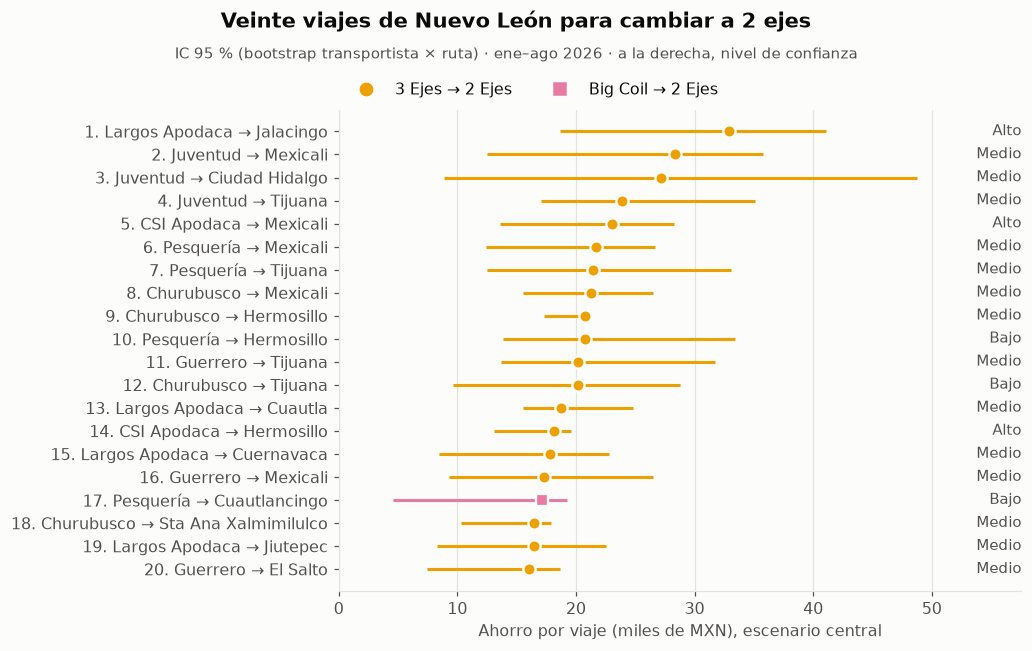

In [7]:
# FIG — ahorro de los 20 viajes con su IC 95 % (forma del marcador = unidad actual; texto = nivel de confianza)
r = sel.iloc[::-1]
y = np.arange(len(r))
fig, ax = plt.subplots(figsize=(9.5, 6.0))
MARCA = {'3 Ejes': 'o', 'Big Coil': 's'}
for u, mk in MARCA.items():
    m = (r['De'] == u).to_numpy()
    ax.errorbar(r['Ahorro'][m] / 1e3, y[m], xerr=[(r['Ahorro'] - r['IC_inf'])[m] / 1e3, (r['IC_sup'] - r['Ahorro'])[m] / 1e3],
                fmt=mk, ms=8, color=tc.COLOR_UNIDAD[u], ecolor=tc.COLOR_UNIDAD[u], elinewidth=2, capsize=0,
                markeredgecolor=tc.SUPERFICIE, markeredgewidth=1.5, zorder=3)
ax.set_yticks(y, [f'{i}. {t}' for i, t in zip(r.index, r['Ruta'])])
ax.set_xlim(0, r['IC_sup'].max() / 1e3 * 1.18)
for yy, conf in zip(y, r['Confianza']):
    ax.text(ax.get_xlim()[1], yy, conf, ha='right', va='center', color=tc.TINTA_2, fontsize=9.5)
ax.set_xlabel('Ahorro por viaje (miles de MXN), escenario central')
ax.grid(axis='y', visible=False)
ax.set_axisbelow(True)
ax.legend(handles=[Line2D([], [], marker=mk, ls='', ms=8, color=tc.COLOR_UNIDAD[u], label=f'{u} → 2 Ejes') for u, mk in MARCA.items()],
          loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.3)
tc.titulo(fig, 'Veinte viajes de Nuevo León para cambiar a 2 ejes',
          'IC 95 % (bootstrap transportista × ruta) · ene–ago 2026 · a la derecha, nivel de confianza')
fig.subplots_adjust(top=0.83)                  # la leyenda va arriba del gráfico, debajo del subtítulo
fig.savefig(OUT / 'componente_5_viajes.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Lectura

- **Casi todo el ahorro creíble está en Nuevo León.** De los 15.53 M MXN del escenario central de C4, 15.26 M (2,112 viajes) salen de plantas de Nuevo León con movimientos 3 ejes o Big Coil → 2 ejes. En 1,427 de esos viajes (11.93 M) el IC del 95 % excluye el cero.
- **Los 20 viajes ahorran $0.42 M en conjunto** (entre $16,000 y $33,000 cada uno). Siguen siendo positivos con la prima pesimista de 12.7 % ($0.35 M). Cada uno representa una ruta: sus 20 rutas suman 235 viajes iguales y 4.66 M MXN, el 31 % del ahorro de los candidatos de Nuevo León. **La acción es por ruta, no por viaje aislado.**
- **19 de 20 son 3 ejes → 2 ejes**, sobre todo hacia el noroeste (Mexicali, Tijuana, Hermosillo). En esas rutas largas la diferencia de tarifa es grande. Solo aparece un Big Coil → 2 ejes (Pesquería → Cuautlancingo): ese movimiento ahorra menos por viaje porque sus rutas son más cortas.
- **Confianza:** 3 altos (Largos Apodaca → Jalacingo, CSI Apodaca → Mexicali y CSI Apodaca → Hermosillo), 14 medios y 3 bajos. Los riesgos más frecuentes son la **flota al tope** (11 viajes: la planta ya usaría esa semana casi todos los 2 ejes que ha conseguido) y el **peso arriba de 26.4 t** (10 viajes: en la práctica los 2 ejes casi nunca cargan más). Antes de aplicar la acción hay que confirmar con los transportistas que pueden surtir el 2 ejes adicional y que el 2 ejes acepta esa carga.
- **Límites.** El IC solo mide la incertidumbre de las tarifas. Los supuestos (flota P90, prima 6.7 %) se fijan como en el escenario central de C4. Los viajes ya ocurrieron: lo que se recomienda es pedir 2 ejes en los **próximos** viajes de esas rutas con cargas parecidas. Su ahorro ya está dentro de los 15.5 M de C4, no se suma.